## Project Overview
Predicting house prices in Sri Lanka using real property 
listings collected from ikman.lk

## Dataset
- Source: Kaggle — Sri Lanka Property Ads Dataset
- Original size: 203,874 rows

## Objective
Build a machine learning model to predict house prices

In [1]:
import pandas as pd
df = pd.read_csv('properties.csv')

In [2]:
pd.set_option('display.max_colwidth', None)
df.head(3)

,ad_title,ad_description,details,slug,title,type,price,timestamp,posted_date,deactivation_date,...,is_doorstep_delivery,is_dsd_applicable,is_member,is_authorized_dealer,is_featured_member,is_verified,membership_level,member_since,properties,user
0,apartment for sale in colombo 05 | ikman,Project: Aquaria by Access Residencies.\n\nSq.Ft. Area: 1363\n\nbeds: 03\nbaths: 02\nkitchen/pantry\nliving/dining\nmaids room and washroom\n\nAvailable units: 01,"Bedrooms: 3, Bathrooms: 2",apartment-for-sale-in-colombo-05-for-sale-colombo-73,apartment for sale in colombo 05,for_sale,"Rs 59,500,000",16 Feb 2:38 pm,2023-02-16T14:38:34+05:30,2022-01-31T04:43:32.000Z,...,False,False,True,False,False,True,plus,October 2016,"{'Address': 'kirimandala mawatha, colombo 05.', 'Bedrooms': '3', 'Bathrooms': '2', 'Size': '1,363 sqft'}",2a36021370cdd0f50da19f64d17ad43be687d48568ec1295c7f0953c91cc590a
1,Land for Sale in Kurunegala | ikman.lk,à·à·à¶à·âà¶»à¶ºà·à¶±à· à¶¯à·à¶ºà·à¶«à· à·à·à¶± à¶à·à¶»à·à¶«à·à¶à¶½à·à¶±à· à·à·à¶³à¶¸ à¶à¶ºà·à¶¢à¶±à¶ºà¶à·\nà¶¸à¶°à·âà¶ºà¶¸ à¶ à¶°à·à·à·à¶à· à¶´à·à·à·à·à·à¶¸à¶§ à·à·à¶±à·à¶©à· 5à¶ºà·\nà·à·à¶ºà¶½à·à¶¸ à¶´à·à·à·à¶à¶¸à· à·à·à·à¶­ à¶à·à¶»à·à¶«à·à¶à¶½ à¶±à¶à¶»à¶ºà¶§ à·à·à¶±à·à¶©à· 5à¶ºà·\nà¶±à·à¶»à·à·à¶½à· à¶à¶´à·à¶´à·\nà¶­à·à¶à¶½à· à·à·à¶¯à·à¶½à·à¶º \nà¶´à·à·à· à¶à·à·à·à¶¸à·...,15.0 perches,land-for-sale-in-kurunegala-for-sale-kurunegala-3583,Land for Sale in Kurunegala,for_sale,"Rs 50,000 per perch",10 Nov 12:06 pm,2022-11-10T12:06:19+05:30,2022-07-30T09:30:41.000Z,...,False,False,True,False,False,False,premium,April 2017,"{'Address': 'kurunegala,malkaduwawa', 'Land type': 'Commercial, Residential', 'Land size': '15.0 perches'}",f917ed789e936ada5530694ede4edde85fdb53f739c5f61cd70292cc70af457a
2,Land for Sale in Kelaniya | ikman,"Good Residential Bare Land in Kelaniya\nLocated Off Kohalwila Road, Kelaniya\n\nHighly residential secure and convenient location\n\n20 Feet Road access\n\n500 Mtrs to Kandy Roa...",18.5 perches,land-for-sale-in-kelaniya-for-sale-gampaha-766,Land for Sale in Kelaniya,for_sale,"Rs 1,600,000 per perch",30 Jan 8:54 am,2023-01-30T08:54:35+05:30,2022-07-30T09:31:26.000Z,...,False,False,True,False,False,True,premium,August 2016,"{'Address': 'Dalugama, Kelaniya', 'Land type': 'Residential, Other', 'Land size': '18.5 perches'}",147c45b684bfeae3e3ffb0397b126d4e67392ad600e254948cbee5cb32f326bf


In [3]:
print("Full dataset shape:", df.shape)
print('\n',df.columns)
print('\n',df['category'].head(10))

Full dataset shape: (203874, 26)

 Index(['ad_title', 'ad_description', 'details', 'slug', 'title', 'type',
       'price', 'timestamp', 'posted_date', 'deactivation_date', 'category',
       'parent_category', 'location', 'geo_region', 'area', 'is_delivery_free',
       'is_doorstep_delivery', 'is_dsd_applicable', 'is_member',
       'is_authorized_dealer', 'is_featured_member', 'is_verified',
       'membership_level', 'member_since', 'properties', 'user'],
      dtype='object')

 0    Apartments For Sale
1                   Land
2          Land For Sale
3          Land For Sale
4        Houses For Sale
5                   Land
6                   Land
7                   Land
8      Apartment Rentals
9        Houses For Sale
Name: category, dtype: object


In [4]:
print(df['category'].unique())
print('\n',df['category'].value_counts())

['Apartments For Sale' 'Land' 'Land For Sale' 'Houses For Sale'
 'Apartment Rentals' 'Commercial Property Rentals' 'House Rentals'
 'Commercial Properties For Sale' 'Holiday & Short-Term Rental'
 'Room & Annex Rentals' 'Land Rentals' 'New Projects']

 category
Land For Sale                     82324
Houses For Sale                   52193
Land                              27155
House Rentals                     15179
Apartment Rentals                  7221
Apartments For Sale                5198
Room & Annex Rentals               4609
Commercial Property Rentals        4541
Commercial Properties For Sale     2752
Holiday & Short-Term Rental        2533
Land Rentals                        134
New Projects                         35
Name: count, dtype: int64


#### There are exactly 52,193 rows representing houses for sale.

### Create a dataset that includes only houses for sale records.

In [5]:
houses_df = df[df['category']== 'Houses For Sale'].copy()
houses_df.head(10)

,ad_title,ad_description,details,slug,title,type,price,timestamp,posted_date,deactivation_date,...,is_doorstep_delivery,is_dsd_applicable,is_member,is_authorized_dealer,is_featured_member,is_verified,membership_level,member_since,properties,user
4,Semi Luxury House for Sale in Kadawatha | ikman,Semi Luxury House in Kadawatha\nLocated at Pinthaliya Road\n\nJest about 100 meters to Kandy Road\n\nHouse consisting of 2 levels with roof terrace\n\nâ¼ Ground Floor (1658 Sq ft...,"Bedrooms: 5, Bathrooms: 4",semi-luxury-house-for-sale-in-kadawatha-for-sale-gampaha,Semi Luxury House for Sale in Kadawatha,for_sale,"Rs 55,000,000",30 Jan 8:54 am,2023-01-30T08:54:09+05:30,2021-10-03T08:33:36.000Z,...,False,False,True,False,False,True,premium,August 2016,"{'Address': 'Pinthaliya Road, Kadawatha', 'Bedrooms': '5', 'Bathrooms': '4', 'House size': '3,000.0 sqft', 'Land size': '27.5 perches'}",147c45b684bfeae3e3ffb0397b126d4e67392ad600e254948cbee5cb32f326bf
9,Two Story House for Sale in Dehiwela | ikman,Kadawatha Road Dehiwala \n4 bedrooms 4 bathrooms pantry and wet kitchen maid room and bathroom small store room fully A/C and full solar power\n2 Car park Available\nPrice :...,"Bedrooms: 4, Bathrooms: 4",two-story-house-for-sale-in-dehiwela-for-sale-colombo-6,Two Story House for Sale in Dehiwela,for_sale,"Rs 80,000,000",14 Feb 10:31 pm,2023-02-14T22:31:10+05:30,2022-01-30T17:38:24.000Z,...,False,False,True,False,False,True,premium,February 2021,"{'Address': 'kadawatha Road', 'Bedrooms': '4', 'Bathrooms': '4', 'House size': '3,000.0 sqft', 'Land size': '8.75 perches'}",765b8447b8c0b5fd5027da030129879e06ca0e744dc8da21b44f8b7f29ff7305
21,House for Sale in Mount Lavinia | ikman,A Two-story British style house for sale in Mount Lavinia\nLocated Off temples Road\n\nPeaceful surroundings & Exclusive Neighborhood\n\nâ¦ First Floor \nOne bed room and a comm...,"Bedrooms: 4, Bathrooms: 2",house-for-sale-in-mount-lavinia-for-sale-colombo-745,House for Sale in Mount Lavinia,for_sale,"Rs 125,000,000",30 Jan 8:54 am,2023-01-30T08:54:39+05:30,2022-07-30T10:15:29.000Z,...,False,False,True,False,False,True,premium,August 2016,"{'Address': 'Off Temple Road, Mount Lavinia', 'Bedrooms': '4', 'Bathrooms': '2', 'House size': '5,600.0 sqft', 'Land size': '20.0 perches'}",147c45b684bfeae3e3ffb0397b126d4e67392ad600e254948cbee5cb32f326bf
22,Luxurious House for sale in Hokandara Malabe | ikman,Description\n\nLuxury Villa for sale in Hokandara \nNear Athurugiriya Highway exit - 58 Million\n\nDescriptions \nâ¾Beds 4\nâ¾Baths 3\nâ¾Land extent 16P\nâ¾House size 4000\n#ï¸â£Ground f...,"Bedrooms: 4, Bathrooms: 3",luxurious-house-for-sale-in-hokandara-malabe-for-sale-colombo,Luxurious House for sale in Hokandara Malabe,for_sale,"Rs 58,000,000",07 Jan 12:01 pm,2023-01-07T12:01:31+05:30,2022-05-30T05:44:29.000Z,...,False,False,True,False,False,True,premium,January 2017,"{'Bedrooms': '4', 'Bathrooms': '3', 'House size': '4,000.0 sqft', 'Land size': '16.0 perches'}",1055f51db0e8b8f4b78aae48f33af949247549d70880373c0e12e1bedf269d35
24,Uncompleted House for Sale in Kotte | ikman.lk,Uncompleted HOUSE FOR SALE IN Kotte ðï¸\n\nLand Size-6.5 Perches \nHouse Size-2200Sqft\n\n*4 Bedrooms ðï¸ðï¸ðï¸ðï¸ \n*3 Bathrooms \n*Living Area \n*Dinning Area \n*Big Kitchen Wit...,"Bedrooms: 4, Bathrooms: 3",uncompleted-house-for-sale-in-kotte-for-sale-colombo-1,Uncompleted House for Sale in Kotte,for_sale,"Rs 22,000,000",30 Oct 1:44 pm,2022-10-30T13:44:14+05:30,2022-07-29T12:01:42.000Z,...,False,False,True,False,False,False,premium,January 2019,"{'Address': 'Kotte', 'Bedrooms': '4', 'Bathrooms': '3', 'House size': '2,200.0 sqft', 'Land size': '6.5 perches'}",9a3fb9c590d014047dff6a0c8337c6038670c47277a79c81e4301ad73e8fc153
31,Luxury Villa House for Sale in Hokandara | ikman.lk,Description\n\nLuxury Villa for sale in Hokandara \nNear Athurugiriya Highway exit - 58 Million\n\nDescriptions \nâ¾Beds 4\nâ¾Baths 3\nâ¾Land extent 16P\nâ¾House size 4000\n#ï¸â£Ground f...,"Bedro

In [6]:
houses_df['type'].value_counts()

type
for_sale    51890
to_buy        303
Name: count, dtype: int64

##### Extracting only for_sale data

In [7]:
houses_df = houses_df[houses_df['type']== 'for_sale']
houses_df[['category','type']].value_counts()

category         type    
Houses For Sale  for_sale    51890
Name: count, dtype: int64

In [8]:
houses_df['properties'].iloc[4]

"{'Address': 'Kotte', 'Bedrooms': '4', 'Bathrooms': '3', 'House size': '2,200.0 sqft', 'Land size': '6.5 perches'}"

##### The data in the properties column is in JSON format.

#### Convert the JSON data in the properties column into Python dictionaries

In [9]:
print(type(houses_df['properties'].iloc[0]))

<class 'str'>


In [10]:
import ast
def parse_props(x):
    try:
        return ast.literal_eval(x)
    except Exception as e:
        print(e)
        return {}
houses_df['properties'] = houses_df['properties'].apply(parse_props)

In [11]:
houses_df['properties'].iloc[4]

{'Address': 'Kotte',
 'Bedrooms': '4',
 'Bathrooms': '3',
 'House size': '2,200.0 sqft',
 'Land size': '6.5 perches'}

In [12]:
houses_df['bedrooms']   = houses_df['properties'].apply(lambda x: x.get('Bedrooms'))
houses_df['bathrooms']  = houses_df['properties'].apply(lambda x: x.get('Bathrooms'))
houses_df['house_size'] = houses_df['properties'].apply(lambda x: x.get('House size'))
houses_df['land_size']  = houses_df['properties'].apply(lambda x: x.get('Land size'))
houses_df['address']    = houses_df['properties'].apply(lambda x: x.get('Address'))

In [13]:
houses_df[['bedrooms', 'bathrooms','house_size', 'land_size','address' ]].iloc[4]

bedrooms                 4
bathrooms                3
house_size    2,200.0 sqft
land_size      6.5 perches
address              Kotte
Name: 24, dtype: object

In [14]:
print("Working dataframe shape:", houses_df.shape)

Working dataframe shape: (51890, 31)


In [15]:
print(houses_df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 51890 entries, 4 to 203872
Data columns (total 31 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   ad_title              51890 non-null  object
 1   ad_description        51890 non-null  object
 2   details               51890 non-null  object
 3   slug                  51890 non-null  object
 4   title                 51890 non-null  object
 5   type                  51890 non-null  object
 6   price                 51890 non-null  object
 7   timestamp             51887 non-null  object
 8   posted_date           51887 non-null  object
 9   deactivation_date     51887 non-null  object
 10  category              51890 non-null  object
 11  parent_category       51890 non-null  object
 12  location              51890 non-null  object
 13  geo_region            51890 non-null  object
 14  area                  51890 non-null  object
 15  is_delivery_free      51890 non-null  bo

In [16]:
print(houses_df.isnull().sum())

ad_title                   0
ad_description             0
details                    0
slug                       0
title                      0
type                       0
price                      0
timestamp                  3
posted_date                3
deactivation_date          3
category                   0
parent_category            0
location                   0
geo_region                 0
area                       0
is_delivery_free           0
is_doorstep_delivery       0
is_dsd_applicable          0
is_member               1375
is_authorized_dealer    1375
is_featured_member      1375
is_verified                0
membership_level           0
member_since            6646
properties                 0
user                       0
bedrooms                   0
bathrooms                  0
house_size                 0
land_size                  0
address                 6097
dtype: int64


In [17]:
houses_df.head(3)

,ad_title,ad_description,details,slug,title,type,price,timestamp,posted_date,deactivation_date,...,is_verified,membership_level,member_since,properties,user,bedrooms,bathrooms,house_size,land_size,address
4,Semi Luxury House for Sale in Kadawatha | ikman,Semi Luxury House in Kadawatha\nLocated at Pinthaliya Road\n\nJest about 100 meters to Kandy Road\n\nHouse consisting of 2 levels with roof terrace\n\nâ¼ Ground Floor (1658 Sq ft...,"Bedrooms: 5, Bathrooms: 4",semi-luxury-house-for-sale-in-kadawatha-for-sale-gampaha,Semi Luxury House for Sale in Kadawatha,for_sale,"Rs 55,000,000",30 Jan 8:54 am,2023-01-30T08:54:09+05:30,2021-10-03T08:33:36.000Z,...,True,premium,August 2016,"{'Address': 'Pinthaliya Road, Kadawatha', 'Bedrooms': '5', 'Bathrooms': '4', 'House size': '3,000.0 sqft', 'Land size': '27.5 perches'}",147c45b684bfeae3e3ffb0397b126d4e67392ad600e254948cbee5cb32f326bf,5,4,"3,000.0 sqft",27.5 perches,"Pinthaliya Road, Kadawatha"
9,Two Story House for Sale in Dehiwela | ikman,Kadawatha Road Dehiwala \n4 bedrooms 4 bathrooms pantry and wet kitchen maid room and bathroom small store room fully A/C and full solar power\n2 Car park Available\nPrice :...,"Bedrooms: 4, Bathrooms: 4",two-story-house-for-sale-in-dehiwela-for-sale-colombo-6,Two Story House for Sale in Dehiwela,for_sale,"Rs 80,000,000",14 Feb 10:31 pm,2023-02-14T22:31:10+05:30,2022-01-30T17:38:24.000Z,...,True,premium,February 2021,"{'Address': 'kadawatha Road', 'Bedrooms': '4', 'Bathrooms': '4', 'House size': '3,000.0 sqft', 'Land size': '8.75 perches'}",765b8447b8c0b5fd5027da030129879e06ca0e744dc8da21b44f8b7f29ff7305,4,4,"3,000.0 sqft",8.75 perches,kadawatha Road
21,House for Sale in Mount Lavinia | ikman,A Two-story British style house for sale in Mount Lavinia\nLocated Off temples Road\n\nPeaceful surroundings & Exclusive Neighborhood\n\nâ¦ First Floor \nOne bed room and a comm...,"Bedrooms: 4, Bathrooms: 2",house-for-sale-in-mount-lavinia-for-sale-colombo-745,House for Sale in Mount Lavinia,for_sale,"Rs 125,000,000",30 Jan 8:54 am,2023-01-30T08:54:39+05:30,2022-07-30T10:15:29.000Z,...,True,premium,August 2016,"{'Address': 'Off Temple Road, Mount Lavinia', 'Bedrooms': '4', 'Bathrooms': '2', 'House size': '5,600.0 sqft', 'Land size': '20.0 perches'}",147c45b684bfeae3e3ffb0397b126d4e67392ad600e254948cbee5cb32f326bf,4,2,"5,600.0 sqft",20.0 perches,"Off Temple Road, Mount Lavinia"


## Basic Data Cleaning Before EDA

#### converting data types

In [18]:
print(houses_df['bedrooms'].unique())
print(houses_df['bathrooms'].unique())




['5' '4' '3' '6' '10' '7' '8' '9' '2' '1' '10+']
['4' '2' '3' '1' '6' '5' '7' '8' '10+' '10' '9']


In [19]:
houses_df['bedrooms'].value_counts()

bedrooms
3      17918
4      17281
5       7636
2       4613
6       2520
1        651
7        532
8        358
10       148
10+      122
9        111
Name: count, dtype: int64

#### Converting the value 10+ to 10, assuming it represents at least 10

In [20]:
houses_df['bedrooms'] = pd.to_numeric(houses_df['bedrooms'].str.replace('+', '', regex=False))
houses_df['bathrooms'] =  pd.to_numeric(houses_df['bathrooms'].str.replace('+', '', regex=False))


#### Converting price column in to integer type

In [21]:
(houses_df['price'] == 'Negotiable').sum()

np.int64(2)

In [22]:
houses_df['price'] = pd.to_numeric(
    houses_df['price'].str.replace('Rs', '', regex=False).str.replace(',','',regex=False),
    errors='coerce'
)

In [23]:
houses_df['price'].isna().sum()

np.int64(2)

In [24]:
houses_df = houses_df.dropna(subset=['price'])
houses_df['price'].isna().sum()

np.int64(0)

#### converting data types of house_size,land_size in to integer type

In [25]:
houses_df['house_size'] = houses_df['house_size'].str.replace('sqft','',regex=False).str.replace(',','',regex=False).astype(float)


In [26]:
def convert_land_size(x):
    if pd.isna(x):
        return None
    x = x.strip()
    if 'acres' in x:
        num = float(x.replace('acres', '').replace(',', '').strip())
        return num * 160  # 1 acre = 160 perches
    elif 'perches' in x:
        num = float(x.replace('perches', '').replace(',', '').strip())
        return num
    else:
        return None

houses_df['land_size'] = houses_df['land_size'].apply(convert_land_size)

In [27]:
houses_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 51888 entries, 4 to 203872
Data columns (total 31 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ad_title              51888 non-null  object 
 1   ad_description        51888 non-null  object 
 2   details               51888 non-null  object 
 3   slug                  51888 non-null  object 
 4   title                 51888 non-null  object 
 5   type                  51888 non-null  object 
 6   price                 51888 non-null  float64
 7   timestamp             51885 non-null  object 
 8   posted_date           51885 non-null  object 
 9   deactivation_date     51885 non-null  object 
 10  category              51888 non-null  object 
 11  parent_category       51888 non-null  object 
 12  location              51888 non-null  object 
 13  geo_region            51888 non-null  object 
 14  area                  51888 non-null  object 
 15  is_delivery_free      5

In [28]:
houses_df = houses_df.reset_index(drop=True)

In [29]:
houses_df.head(3)

,ad_title,ad_description,details,slug,title,type,price,timestamp,posted_date,deactivation_date,...,is_verified,membership_level,member_since,properties,user,bedrooms,bathrooms,house_size,land_size,address
0,Semi Luxury House for Sale in Kadawatha | ikman,Semi Luxury House in Kadawatha\nLocated at Pinthaliya Road\n\nJest about 100 meters to Kandy Road\n\nHouse consisting of 2 levels with roof terrace\n\nâ¼ Ground Floor (1658 Sq ft...,"Bedrooms: 5, Bathrooms: 4",semi-luxury-house-for-sale-in-kadawatha-for-sale-gampaha,Semi Luxury House for Sale in Kadawatha,for_sale,55000000.0,30 Jan 8:54 am,2023-01-30T08:54:09+05:30,2021-10-03T08:33:36.000Z,...,True,premium,August 2016,"{'Address': 'Pinthaliya Road, Kadawatha', 'Bedrooms': '5', 'Bathrooms': '4', 'House size': '3,000.0 sqft', 'Land size': '27.5 perches'}",147c45b684bfeae3e3ffb0397b126d4e67392ad600e254948cbee5cb32f326bf,5,4,3000.0,27.50,"Pinthaliya Road, Kadawatha"
1,Two Story House for Sale in Dehiwela | ikman,Kadawatha Road Dehiwala \n4 bedrooms 4 bathrooms pantry and wet kitchen maid room and bathroom small store room fully A/C and full solar power\n2 Car park Available\nPrice :...,"Bedrooms: 4, Bathrooms: 4",two-story-house-for-sale-in-dehiwela-for-sale-colombo-6,Two Story House for Sale in Dehiwela,for_sale,80000000.0,14 Feb 10:31 pm,2023-02-14T22:31:10+05:30,2022-01-30T17:38:24.000Z,...,True,premium,February 2021,"{'Address': 'kadawatha Road', 'Bedrooms': '4', 'Bathrooms': '4', 'House size': '3,000.0 sqft', 'Land size': '8.75 perches'}",765b8447b8c0b5fd5027da030129879e06ca0e744dc8da21b44f8b7f29ff7305,4,4,3000.0,8.75,kadawatha Road
2,House for Sale in Mount Lavinia | ikman,A Two-story British style house for sale in Mount Lavinia\nLocated Off temples Road\n\nPeaceful surroundings & Exclusive Neighborhood\n\nâ¦ First Floor \nOne bed room and a comm...,"Bedrooms: 4, Bathrooms: 2",house-for-sale-in-mount-lavinia-for-sale-colombo-745,House for Sale in Mount Lavinia,for_sale,125000000.0,30 Jan 8:54 am,2023-01-30T08:54:39+05:30,2022-07-30T10:15:29.000Z,...,True,premium,August 2016,"{'Address': 'Off Temple Road, Mount Lavinia', 'Bedrooms': '4', 'Bathrooms': '2', 'House size': '5,600.0 sqft', 'Land size': '20.0 perches'}",147c45b684bfeae3e3ffb0397b126d4e67392ad600e254948cbee5cb32f326bf,4,2,5600.0,20.00,"Off Temple Road, Mount Lavinia"


# Exploratory Data Analysis

## bedrooms Destribution

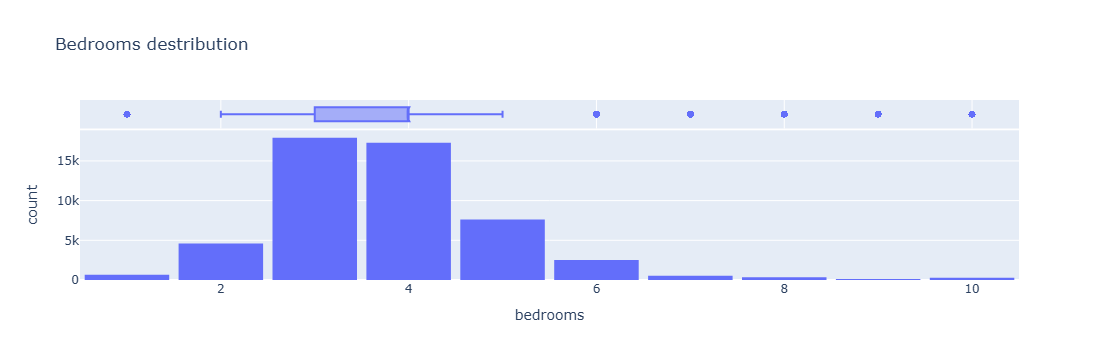

In [30]:
import plotly.express as px
figure = px.histogram(houses_df,
                     x='bedrooms',
                     marginal ='box',
                     nbins = 10,
                     title='Bedrooms destribution')
figure.update_layout(bargap=0.1)
figure.show()

- The distribution of bedrooms is right-skewed. This means that most houses in the dataset have 3 or 4 bedrooms. The number of listings decreases as the bedroom count increases, indicating that larger houses are less common. The distribution is concentrated around 3 to 5 bedrooms, with very few houses having 8 or more bedrooms.Houses with more than 6 bedrooms appear as outliers in the bedroom distribution because they are much less common compared to typical residential properties. However, these values should not necessarily be removed because Sri Lanka has large ancestral homes, luxury villas, and estate-style properties that can naturally contain 7 or more bedrooms

### bathrooms destribution

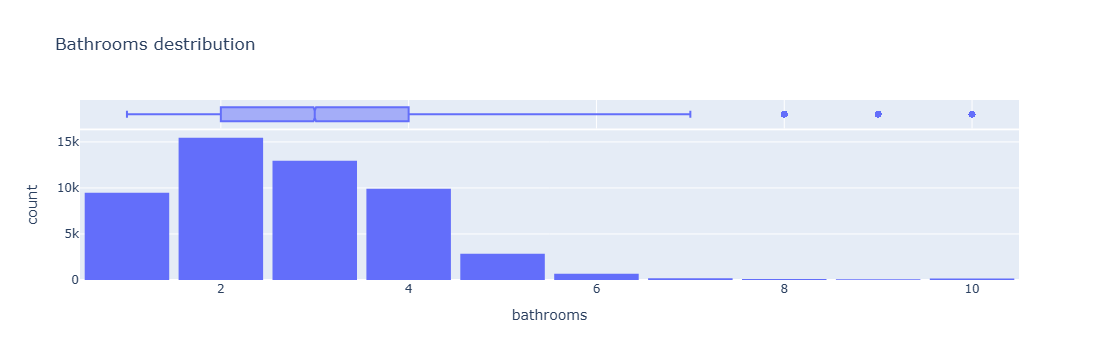

In [31]:
figure = px.histogram(houses_df,
                     x='bathrooms',
                     marginal ='box',
                     nbins = 10,
                     title='Bathrooms destribution')
figure.update_layout(bargap=0.1)
figure.show()

- The distribution also is right skewed. This means most houses in the dataset have 2 to 4 bathrooms. The number of listings alos decreases as 
the bathroom count increases, indicating that largerhouses are less common like the bedrooms destribution.Same as bedrooms we cant ingnore or remove these outliers as well.

In [32]:
houses_df['bathrooms'].value_counts()

bathrooms
2     15450
3     12960
4      9923
1      9483
5      2865
6       672
7       203
10      160
8        95
9        77
Name: count, dtype: int64

In [33]:
houses_df[['price','bathrooms','bedrooms','house_size','land_size']].describe()

,price,bathrooms,bedrooms,house_size,land_size
count,5.188800e+04,51888.000000,51888.000000,51888.000000,51888.000000
mean,5.838041e+07,2.732539,3.783823,2670.177824,19.388779
std,3.951135e+09,1.341207,1.245805,5612.087094,341.239342
min,7.000000e+00,1.000000,1.000000,0.000000,0.000000
25%,1.700000e+07,2.000000,3.000000,1525.000000,7.360000
50%,2.850000e+07,3.000000,4.000000,2350.000000,10.000000
75%,4.750000e+07,4.000000,4.000000,3200.000000,12.500000
max,9.000000e+11,10.000000,10.000000,900000.000000,62500.000000


In [34]:
houses_df[['price', 'bathrooms', 'bedrooms', 'house_size', 'land_size']].quantile(0.5)

price         28500000.0
bathrooms            3.0
bedrooms             4.0
house_size        2350.0
land_size           10.0
Name: 0.5, dtype: float64

- The mean price (Rs 58.3M) is much higher than the median (Rs 28.5M), showing extreme right skew 
  caused by extreme unnatural house prices like 900 Billion.
- The minimum price of Rs 7 is clearly a fake or test listing — impossible for a real house.
- 50% of houses are priced between Rs 17M and Rs 47.5M which is realistic for the Sri Lankan market.
- Standard deviation of Rs 3.9 Billion is much higher the mean — which means extreme outliers.

- Average house size is 2,670 sqft, median is 2,350 sqft. Minimum of 0 sqft is physically impossible — data error.
- Maximum of 900,000 sqft is clearly wrong.

- Average land size is 18.3 perches but median is only 10 perches — heavily pulled up by outliers
- Minimum of 0 perches is physically impossible.
- Maximum of 62,500 perches equals 156 acres — 
  clearly not a residential property.
- 75% of houses sit on land below 12.5 perches 
  which is typical for Sri Lankan residential plots.

                         

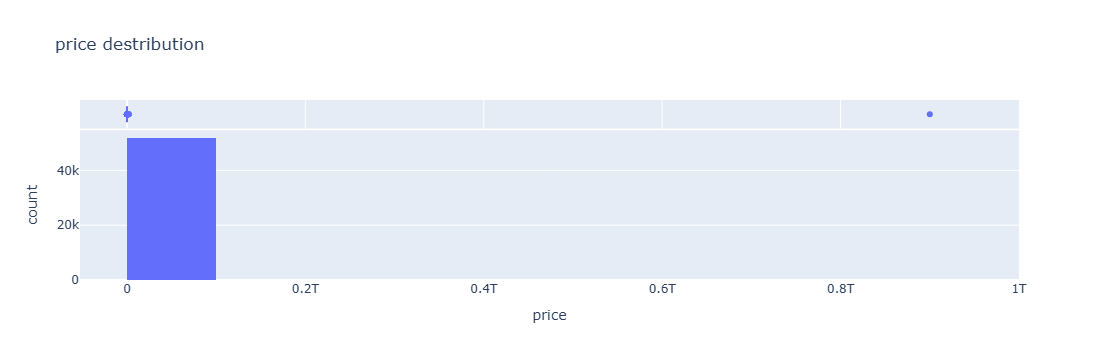

In [35]:
figure = px.histogram(houses_df,
                     x='price',
                     marginal ='box',
                     nbins = 10,
                     title='price destribution')

figure.show()

- The raw price distribution is extremely right skewed
  due to outliers reaching Rs 900 Billion.

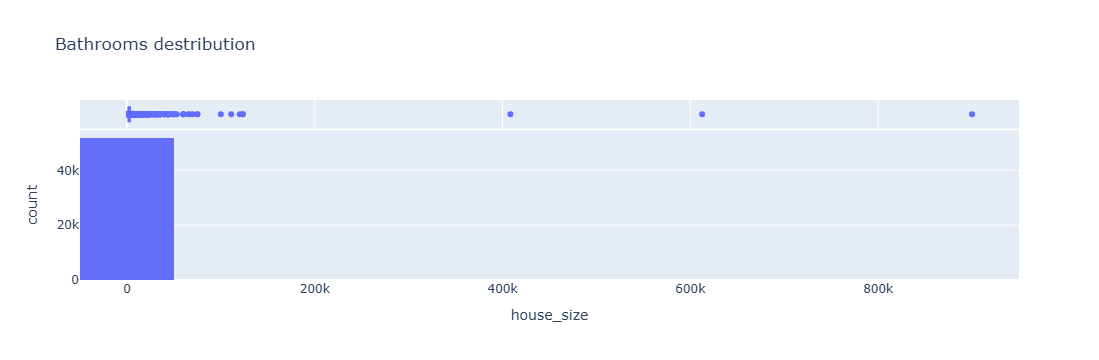

In [36]:
figure = px.histogram(houses_df,
                     x='house_size',
                     marginal ='box',
                     nbins = 10,
                     title='Bathrooms destribution')
figure.show()

- The distribution is also right skewed.

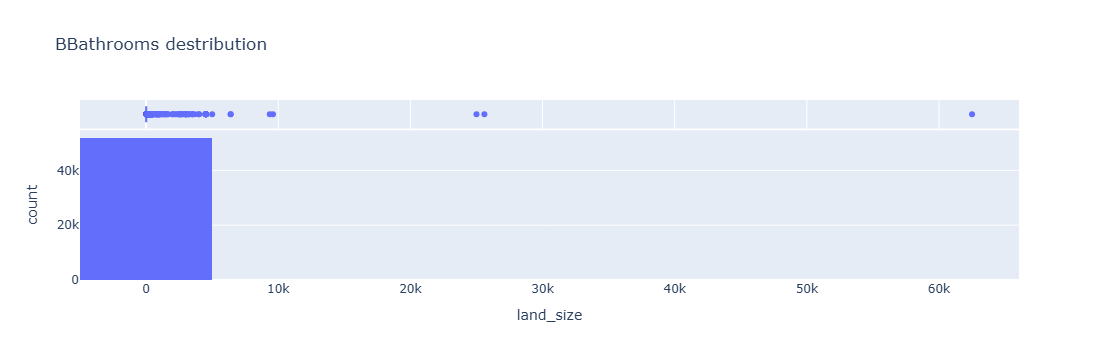

In [37]:
figure = px.histogram(houses_df,
                     x='land_size',
                     marginal ='box',
                     nbins = 10,
                     title='BBathrooms destribution')
figure.show()

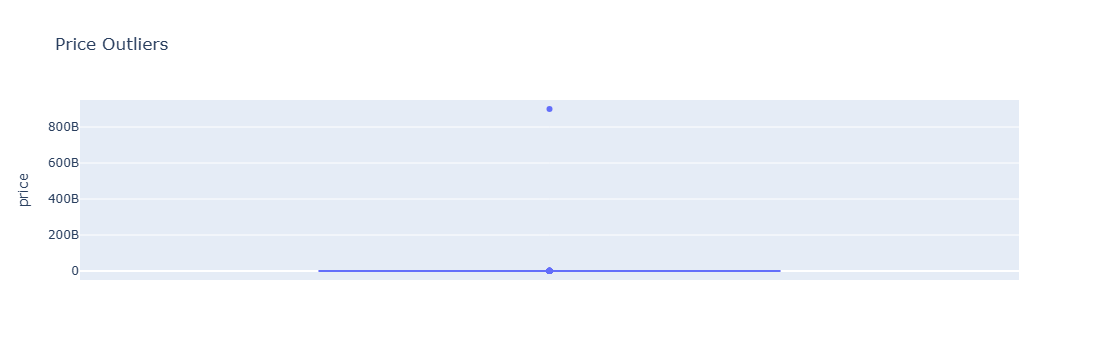

In [38]:
fig = px.box(
    houses_df,
    y='price',
    title='Price Outliers'
)

fig.show()

- The box plot clearly shows the median price 
  at Rs 28.5 Million with the box 
  (25th-75th percentile) between Rs 17M and Rs 47.5M.

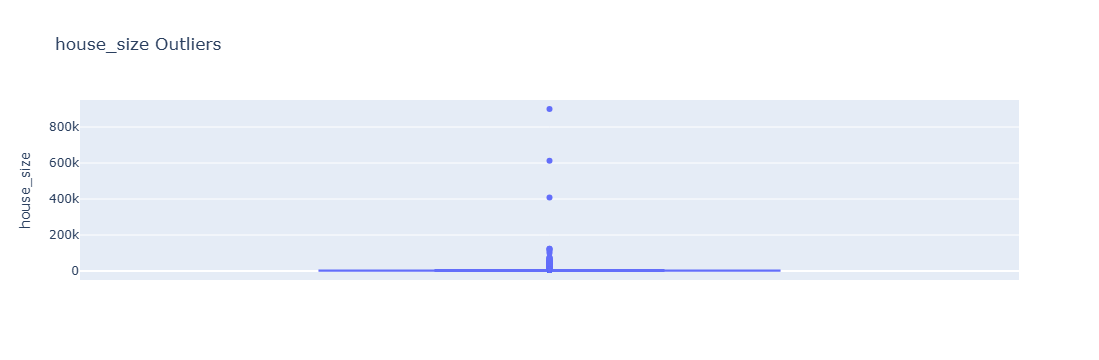

In [39]:
fig = px.box(
    houses_df,
    y='house_size',
    title='house_size Outliers'
)

fig.show()

- The box shows the median at 2,350 sqft with 
  the interquartile range from 1,525 to 3,200 sqft.


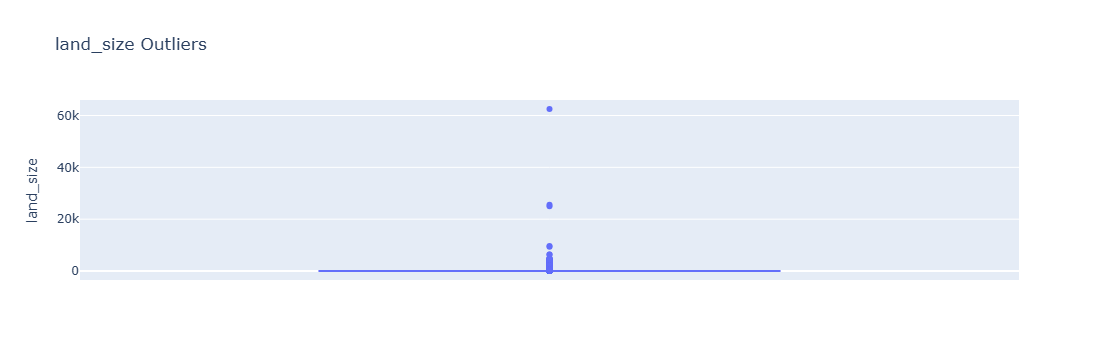

In [40]:
fig = px.box(
    houses_df,
    y='land_size',
    title='land_size Outliers'
)

fig.show()

- The box shows the median at 10 perches with 
  the interquartile range from 7.2 to 12.5 perches.

In [41]:
print('Price Precentiles RS ')
print('minimum price = ', houses_df['price'].min())
print('maximum price = ', houses_df['price'].max())
for p in [0.01, 0.05, 0.25, 0.5, 0.75, 0.95 ,0.99]:
    print(f" {int(p * 100)}th : {houses_df['price'].quantile(p)}")

print('\n house_size Precentiles')
print('minimum house size = ', houses_df['house_size'].min())
print('maximum house size = ', houses_df['house_size'].max())
for p in [0.01, 0.05, 0.25, 0.5, 0.75, 0.95 ,0.99]:
    print(f"{int(p * 100)}th :{houses_df['house_size'].quantile(p)}")

print('\n land_size Precentiles')
print('minimum land_size = ', houses_df['land_size'].min())
print('maximum land_size = ', houses_df['land_size'].max())
for p in [0.01, 0.05, 0.25, 0.5, 0.75, 0.95 ,0.99]:
    print(f"{int(p * 100)}th :{houses_df['land_size'].quantile(p)}")


Price Precentiles RS 
minimum price =  7.0
maximum price =  900000002100.0
 1th : 3143500.0
 5th : 6500000.0
 25th : 17000000.0
 50th : 28500000.0
 75th : 47500000.0
 95th : 120000000.0
 99th : 225000000.0

 house_size Precentiles
minimum house size =  0.0
maximum house size =  900000.0
1th :516.0
5th :1000.0
25th :1525.0
50th :2350.0
75th :3200.0
95th :5000.0
99th :8576.219999999754

 land_size Precentiles
minimum land_size =  0.0
maximum land_size =  62500.0
1th :2.5
5th :6.0
25th :7.36
50th :10.0
75th :12.5
95th :29.1
99th :85.0


- Minimum price of Rs 7 is clearly a fake or test 
  listing — impossible for any real house in Sri Lanka.
- Maximum price of Rs 900 Billion is impossible 
  for a residential property.
- Median (50th): Rs 28.5M — most typical Sri Lankan 
  house price, realistic for suburban properties.
-75th percentile: Rs 47.5M — upper middle market, 
  likely larger houses in good locations
- 95th percentile: Rs 120M — genuinely expensive 
  properties


- Minimum of 0 sqft is physically impossible
-  Maximum of 900,000 sqft is impossible for a 
  residential property — likely a commercial building 
  or massive data entry error.
- 1st percentile: 516 sqft — small but realistic 
  for a compact Sri Lankan house.
- Median: 2,350 sqft — very typical size for 
  a standard Sri Lankan family home.
- 75th percentile: 3,200 sqft — larger houses, 
  likely with garden and multiple floors


- Minimum of 0 perches is physically impossible — 
  4 listings have this value and will be removed.
- Maximum of 62,500 perches equals 156 acres — 
  clearly a farm or plantation, not a house.
- 1st percentile: 2.3 perches — very small plot, 
  realistic for compact urban properties in Colombo.
- Median: 10 perches — very typical residential 
  plot size in Sri Lanka.
- 75th percentile: 12.5 perches — slightly above 
  median, standard suburban plot size.

# Data Cleaning

In [42]:
houses_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51888 entries, 0 to 51887
Data columns (total 31 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ad_title              51888 non-null  object 
 1   ad_description        51888 non-null  object 
 2   details               51888 non-null  object 
 3   slug                  51888 non-null  object 
 4   title                 51888 non-null  object 
 5   type                  51888 non-null  object 
 6   price                 51888 non-null  float64
 7   timestamp             51885 non-null  object 
 8   posted_date           51885 non-null  object 
 9   deactivation_date     51885 non-null  object 
 10  category              51888 non-null  object 
 11  parent_category       51888 non-null  object 
 12  location              51888 non-null  object 
 13  geo_region            51888 non-null  object 
 14  area                  51888 non-null  object 
 15  is_delivery_free   

In [43]:
houses_df.describe()

,price,bedrooms,bathrooms,house_size,land_size
count,5.188800e+04,51888.000000,51888.000000,51888.000000,51888.000000
mean,5.838041e+07,3.783823,2.732539,2670.177824,19.388779
std,3.951135e+09,1.245805,1.341207,5612.087094,341.239342
min,7.000000e+00,1.000000,1.000000,0.000000,0.000000
25%,1.700000e+07,3.000000,2.000000,1525.000000,7.360000
50%,2.850000e+07,4.000000,3.000000,2350.000000,10.000000
75%,4.750000e+07,4.000000,4.000000,3200.000000,12.500000
max,9.000000e+11,10.000000,10.000000,900000.000000,62500.000000


In [44]:
houses_df = houses_df[(houses_df['house_size'] != 0) &(houses_df['land_size'] != 0)]

In [45]:

# Price: drop unrealistic lows and highs
# Rs 7 is fake; set a realistic floor. Rs 900B+ is impossible.
houses_df = houses_df[
    (houses_df['price'] >= 100000) &      # anything below Rs 100k isn't a real house sale
    (houses_df['price'] < 9e11)           
]

houses_df = houses_df[houses_df['house_size'] <= 20000]  

# convert land sizes into square feet
houses_df['land_size'] = houses_df['land_size'] * 272.25

# ~100 perches = 27225 sqft — anything above is an estate, not a house
houses_df = houses_df[houses_df['land_size'] <= 27225]

In [46]:
print(houses_df.shape)
houses_df[['price','house_size','land_size']].describe()

(51323, 31)


,price,house_size,land_size
count,5.132300e+04,51323.000000,51323.000000
mean,4.107425e+07,2563.739038,3237.156630
std,4.812695e+07,1493.211619,2516.467354
min,1.000000e+05,0.010000,29.947500
25%,1.700000e+07,1525.000000,1973.812500
50%,2.850000e+07,2350.000000,2722.500000
75%,4.750000e+07,3200.000000,3403.125000
max,2.100000e+09,20000.000000,27225.000000


In [47]:
# --- Percentile-based trimming (mild, applied after domain cleaning) ---
for col in ['price', 'house_size', 'land_size']:
    lower = houses_df[col].quantile(0.01)
    upper = houses_df[col].quantile(0.99)
    houses_df = houses_df[(houses_df[col] >= lower) & (houses_df[col] <= upper)]

print(houses_df.shape)

(48541, 31)


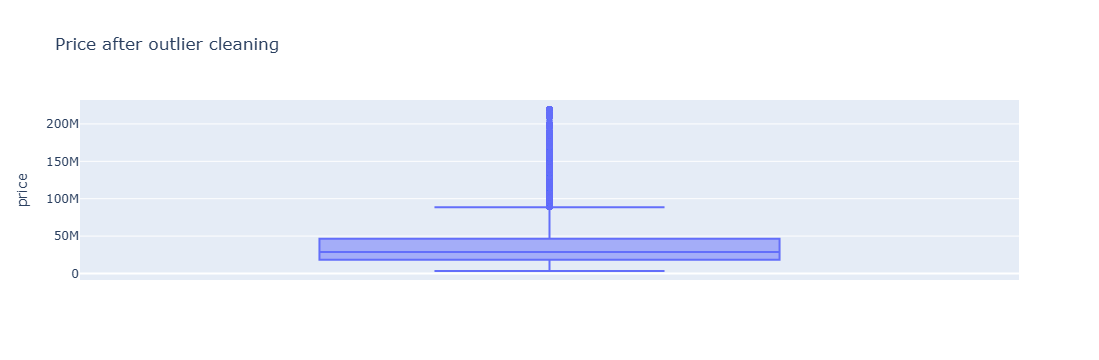

In [48]:
fig = px.box(houses_df, y='price', title='Price after outlier cleaning')
fig.show()

#### box plot now shows: median Rs 28.5M, IQR Rs 18.5M–46M, upper fence Rs 87.25M, max Rs 220M

In [49]:
import numpy as np
houses_df['log_price'] = np.log1p(houses_df['price'])

In [50]:
houses_df.head()

,ad_title,ad_description,details,slug,title,type,price,timestamp,posted_date,deactivation_date,...,membership_level,member_since,properties,user,bedrooms,bathrooms,house_size,land_size,address,log_price
0,Semi Luxury House for Sale in Kadawatha | ikman,Semi Luxury House in Kadawatha\nLocated at Pinthaliya Road\n\nJest about 100 meters to Kandy Road\n\nHouse consisting of 2 levels with roof terrace\n\nâ¼ Ground Floor (1658 Sq ft...,"Bedrooms: 5, Bathrooms: 4",semi-luxury-house-for-sale-in-kadawatha-for-sale-gampaha,Semi Luxury House for Sale in Kadawatha,for_sale,55000000.0,30 Jan 8:54 am,2023-01-30T08:54:09+05:30,2021-10-03T08:33:36.000Z,...,premium,August 2016,"{'Address': 'Pinthaliya Road, Kadawatha', 'Bedrooms': '5', 'Bathrooms': '4', 'House size': '3,000.0 sqft', 'Land size': '27.5 perches'}",147c45b684bfeae3e3ffb0397b126d4e67392ad600e254948cbee5cb32f326bf,5,4,3000.0,7486.8750,"Pinthaliya Road, Kadawatha",17.822844
1,Two Story House for Sale in Dehiwela | ikman,Kadawatha Road Dehiwala \n4 bedrooms 4 bathrooms pantry and wet kitchen maid room and bathroom small store room fully A/C and full solar power\n2 Car park Available\nPrice :...,"Bedrooms: 4, Bathrooms: 4",two-story-house-for-sale-in-dehiwela-for-sale-colombo-6,Two Story House for Sale in Dehiwela,for_sale,80000000.0,14 Feb 10:31 pm,2023-02-14T22:31:10+05:30,2022-01-30T17:38:24.000Z,...,premium,February 2021,"{'Address': 'kadawatha Road', 'Bedrooms': '4', 'Bathrooms': '4', 'House size': '3,000.0 sqft', 'Land size': '8.75 perches'}",765b8447b8c0b5fd5027da030129879e06ca0e744dc8da21b44f8b7f29ff7305,4,4,3000.0,2382.1875,kadawatha Road,18.197537
2,House for Sale in Mount Lavinia | ikman,A Two-story British style house for sale in Mount Lavinia\nLocated Off temples Road\n\nPeaceful surroundings & Exclusive Neighborhood\n\nâ¦ First Floor \nOne bed room and a comm...,"Bedrooms: 4, Bathrooms: 2",house-for-sale-in-mount-lavinia-for-sale-colombo-745,House for Sale in Mount Lavinia,for_sale,125000000.0,30 Jan 8:54 am,2023-01-30T08:54:39+05:30,2022-07-30T10:15:29.000Z,...,premium,August 2016,"{'Address': 'Off Temple Road, Mount Lavinia', 'Bedrooms': '4', 'Bathrooms': '2', 'House size': '5,600.0 sqft', 'Land size': '20.0 perches'}",147c45b684bfeae3e3ffb0397b126d4e67392ad600e254948cbee5cb32f326bf,4,2,5600.0,5445.0000,"Off Temple Road, Mount Lavinia",18.643824
3,Luxurious House for sale in Hokandara Malabe | ikman,Description\n\nLuxury Villa for sale in Hokandara \nNear Athurugiriya Highway exit - 58 Million\n\nDescriptions \nâ¾Beds 4\nâ¾Baths 3\nâ¾Land extent 16P\nâ¾House size 4000\n#ï¸â£Ground f...,"Bedrooms: 4, Bathrooms: 3",luxurious-house-for-sale-in-hokandara-malabe-for-sale-colombo,Luxurious House for sale in Hokandara Malabe,for_sale,58000000.0,07 Jan 12:01 pm,2023-01-07T12:01:31+05:30,2022-05-30T05:44:29.000Z,...,premium,January 2017,"{'Bedrooms': '4', 'Bathrooms': '3', 'House size': '4,000.0 sqft', 'Land size': '16.0 perches'}",1055f51db0e8b8f4b78aae48f33af949247549d70880373c0e12e1bedf269d35,4,3,4000.0,4356.0000,None,17.875954
4,Uncompleted House for Sale in Kotte | ikman.lk,Uncompleted HOUSE FOR SALE IN Kotte ðï¸\n\nLand Size-6.5 Perches \nHouse Size-2200Sqft\n\n*4 Bedrooms ðï¸ðï¸ðï¸ðï¸ \n*3 Bathrooms \n*Living Area \n*Dinning Area \n*Big Kitchen Wit...,"Bedrooms: 4, Bathrooms: 3",uncompleted-house-for-sale-in-kotte-for-sale-colombo-1,Uncompleted House for Sale in Kotte,for_sale,22000000.0,30 Oct 1:44 pm,2022-10-30T13:44:14+05:30,2022-07-29T12:01:42.000Z,...,premium,January 2019,"{'Address': 'Kotte', 'Bedrooms': '4', 'Bathrooms': '3', 'House size': '2,200.0 sqft', 'Land size': '6.5 perches'}",9a3fb9c590d014047dff6a0c8337c6038670c47277a79c81e4301ad73e8fc153,4,3,2200.0,1769.6250,Kotte,16.906553


In [51]:
# cannot remove duplicates with dict types and already exctracted the data as new columns
houses_df = houses_df.drop(columns=['properties'])

In [52]:
pd.set_option('display.max_colwidth', None)
houses_df.head()

,ad_title,ad_description,details,slug,title,type,price,timestamp,posted_date,deactivation_date,...,is_verified,membership_level,member_since,user,bedrooms,bathrooms,house_size,land_size,address,log_price
0,Semi Luxury House for Sale in Kadawatha | ikman,Semi Luxury House in Kadawatha\nLocated at Pinthaliya Road\n\nJest about 100 meters to Kandy Road\n\nHouse consisting of 2 levels with roof terrace\n\nâ¼ Ground Floor (1658 Sq ft...,"Bedrooms: 5, Bathrooms: 4",semi-luxury-house-for-sale-in-kadawatha-for-sale-gampaha,Semi Luxury House for Sale in Kadawatha,for_sale,55000000.0,30 Jan 8:54 am,2023-01-30T08:54:09+05:30,2021-10-03T08:33:36.000Z,...,True,premium,August 2016,147c45b684bfeae3e3ffb0397b126d4e67392ad600e254948cbee5cb32f326bf,5,4,3000.0,7486.8750,"Pinthaliya Road, Kadawatha",17.822844
1,Two Story House for Sale in Dehiwela | ikman,Kadawatha Road Dehiwala \n4 bedrooms 4 bathrooms pantry and wet kitchen maid room and bathroom small store room fully A/C and full solar power\n2 Car park Available\nPrice :...,"Bedrooms: 4, Bathrooms: 4",two-story-house-for-sale-in-dehiwela-for-sale-colombo-6,Two Story House for Sale in Dehiwela,for_sale,80000000.0,14 Feb 10:31 pm,2023-02-14T22:31:10+05:30,2022-01-30T17:38:24.000Z,...,True,premium,February 2021,765b8447b8c0b5fd5027da030129879e06ca0e744dc8da21b44f8b7f29ff7305,4,4,3000.0,2382.1875,kadawatha Road,18.197537
2,House for Sale in Mount Lavinia | ikman,A Two-story British style house for sale in Mount Lavinia\nLocated Off temples Road\n\nPeaceful surroundings & Exclusive Neighborhood\n\nâ¦ First Floor \nOne bed room and a comm...,"Bedrooms: 4, Bathrooms: 2",house-for-sale-in-mount-lavinia-for-sale-colombo-745,House for Sale in Mount Lavinia,for_sale,125000000.0,30 Jan 8:54 am,2023-01-30T08:54:39+05:30,2022-07-30T10:15:29.000Z,...,True,premium,August 2016,147c45b684bfeae3e3ffb0397b126d4e67392ad600e254948cbee5cb32f326bf,4,2,5600.0,5445.0000,"Off Temple Road, Mount Lavinia",18.643824
3,Luxurious House for sale in Hokandara Malabe | ikman,Description\n\nLuxury Villa for sale in Hokandara \nNear Athurugiriya Highway exit - 58 Million\n\nDescriptions \nâ¾Beds 4\nâ¾Baths 3\nâ¾Land extent 16P\nâ¾House size 4000\n#ï¸â£Ground f...,"Bedrooms: 4, Bathrooms: 3",luxurious-house-for-sale-in-hokandara-malabe-for-sale-colombo,Luxurious House for sale in Hokandara Malabe,for_sale,58000000.0,07 Jan 12:01 pm,2023-01-07T12:01:31+05:30,2022-05-30T05:44:29.000Z,...,True,premium,January 2017,1055f51db0e8b8f4b78aae48f33af949247549d70880373c0e12e1bedf269d35,4,3,4000.0,4356.0000,None,17.875954
4,Uncompleted House for Sale in Kotte | ikman.lk,Uncompleted HOUSE FOR SALE IN Kotte ðï¸\n\nLand Size-6.5 Perches \nHouse Size-2200Sqft\n\n*4 Bedrooms ðï¸ðï¸ðï¸ðï¸ \n*3 Bathrooms \n*Living Area \n*Dinning Area \n*Big Kitchen Wit...,"Bedrooms: 4, Bathrooms: 3",uncompleted-house-for-sale-in-kotte-for-sale-colombo-1,Uncompleted House for Sale in Kotte,for_sale,22000000.0,30 Oct 1:44 pm,2022-10-30T13:44:14+05:30,2022-07-29T12:01:42.000Z,...,False,premium,January 2019,9a3fb9c590d014047dff6a0c8337c6038670c47277a79c81e4301ad73e8fc153,4,3,2200.0,1769.6250,Kotte,16.906553


In [53]:
houses_df.isna().sum()

ad_title                   0
ad_description             0
details                    0
slug                       0
title                      0
type                       0
price                      0
timestamp                  3
posted_date                3
deactivation_date          3
category                   0
parent_category            0
location                   0
geo_region                 0
area                       0
is_delivery_free           0
is_doorstep_delivery       0
is_dsd_applicable          0
is_member               1204
is_authorized_dealer    1204
is_featured_member      1204
is_verified                0
membership_level           0
member_since            5288
user                       0
bedrooms                   0
bathrooms                  0
house_size                 0
land_size                  0
address                 5630
log_price                  0
dtype: int64

### Changing datatypes

In [54]:
houses_df['posted_date'] = pd.to_datetime(houses_df['posted_date'] , errors= 'coerce')
houses_df['deactivation_date'] = pd.to_datetime(houses_df['deactivation_date'] , errors= 'coerce')
houses_df['member_since'] = pd.to_datetime(houses_df['member_since'] ,format ='%B %Y', errors= 'coerce')

In [55]:
print(houses_df['posted_date'].isna().sum())
print(houses_df['deactivation_date'].isna().sum())
print(houses_df['member_since'].isna().sum())

3
3
5288


In [56]:
houses_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 48541 entries, 0 to 51887
Data columns (total 31 columns):
 #   Column                Non-Null Count  Dtype                    
---  ------                --------------  -----                    
 0   ad_title              48541 non-null  object                   
 1   ad_description        48541 non-null  object                   
 2   details               48541 non-null  object                   
 3   slug                  48541 non-null  object                   
 4   title                 48541 non-null  object                   
 5   type                  48541 non-null  object                   
 6   price                 48541 non-null  float64                  
 7   timestamp             48538 non-null  object                   
 8   posted_date           48538 non-null  datetime64[ns, UTC+05:30]
 9   deactivation_date     48538 non-null  datetime64[ns, UTC]      
 10  category              48541 non-null  object                   

#### Removing duplicates

In [57]:
houses_df.duplicated().sum()

np.int64(0)

#### Remove unnecessary columns

In [58]:
houses_df = houses_df.drop(columns=['user','slug', 'timestamp', 'deactivation_date','ad_description','ad_title','details','title'])

-`user` Removed because it is a unique user identifier with no meaningful relationship to house prices. 
- `slug` Removed because it is a generated URL identifier and contains duplicated information from the title. 
- `timestamp`  Removed because `posted_date` already contains more complete date and time information. 
- `deactivation_date`  Removed because it does not contribute to price prediction and contains inconsistent values compared with `posted_date`. 
- `ad_title`  Removed because it is text data requiring NLP techniques to extract meaningful features. 
- `ad_description`  Removed because it contains long text descriptions requiring NLP processing, which is beyond the scope of this model. 
- `details`  Removed because important information such as bedrooms and bathrooms has already been extracted into separate numerical columns. 
- `title`  Removed because it contains similar information to `ad_title` 

In [59]:
houses_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 48541 entries, 0 to 51887
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype                    
---  ------                --------------  -----                    
 0   type                  48541 non-null  object                   
 1   price                 48541 non-null  float64                  
 2   posted_date           48538 non-null  datetime64[ns, UTC+05:30]
 3   category              48541 non-null  object                   
 4   parent_category       48541 non-null  object                   
 5   location              48541 non-null  object                   
 6   geo_region            48541 non-null  object                   
 7   area                  48541 non-null  object                   
 8   is_delivery_free      48541 non-null  bool                     
 9   is_doorstep_delivery  48541 non-null  bool                     
 10  is_dsd_applicable     48541 non-null  bool                     

#### Removing null values

In [60]:
houses_df.isna().sum()

type                       0
price                      0
posted_date                3
category                   0
parent_category            0
location                   0
geo_region                 0
area                       0
is_delivery_free           0
is_doorstep_delivery       0
is_dsd_applicable          0
is_member               1204
is_authorized_dealer    1204
is_featured_member      1204
is_verified                0
membership_level           0
member_since            5288
bedrooms                   0
bathrooms                  0
house_size                 0
land_size                  0
address                 5630
log_price                  0
dtype: int64

In [61]:
houses_df['is_authorized_dealer'].value_counts(dropna=False)

is_authorized_dealer
False    47255
NaN       1204
True        82
Name: count, dtype: int64

In [62]:
houses_df['is_member'].value_counts(dropna=False)

is_member
True     42053
False     5284
NaN       1204
Name: count, dtype: int64

In [63]:
houses_df['is_featured_member'].value_counts(dropna=False)

is_featured_member
False    47337
NaN       1204
Name: count, dtype: int64

- This column has zero variation.It has no predictive information.this column should be dropped.

In [64]:
# dropping 'is_featured_member'
houses_df = houses_df.drop(columns = ['is_featured_member'])

In [65]:
houses_df[houses_df['is_member'].isna()][['is_member','is_authorized_dealer']]

,is_member,is_authorized_dealer
1776,NaN,NaN
1804,NaN,NaN
1924,NaN,NaN
2113,NaN,NaN
2196,NaN,NaN
...,...,...
51793,NaN,NaN
51838,NaN,NaN
51852,NaN,NaN
51866,NaN,NaN


- It seems missing values are same in both is_member,is_authorized_dealer columns

In [66]:
houses_df[['is_member','is_authorized_dealer']] = houses_df[['is_member','is_authorized_dealer']].fillna('False')

##### Handling Missing Values in Membership Columns

- The `is_member`, `is_authorized_dealer` columns contained missing values. 
These columns represent boolean (Yes/No) that indicate whether a seller is a member, an authorized dealer

- Since these fields describe seller status, the missing values were replaced with `False`. 
This assumes that if a membership status is not recorded, the seller does not have that particular membership or designation. 
    

In [67]:
houses_df.head()

,type,price,posted_date,category,parent_category,location,geo_region,area,is_delivery_free,is_doorstep_delivery,...,is_authorized_dealer,is_verified,membership_level,member_since,bedrooms,bathrooms,house_size,land_size,address,log_price
0,for_sale,55000000.0,2023-01-30 08:54:09+05:30,Houses For Sale,Property,Kadawatha,LK-12,"{'id': 1577, 'name': 'Gampaha'}",False,False,...,False,True,premium,2016-08-01,5,4,3000.0,7486.8750,"Pinthaliya Road, Kadawatha",17.822844
1,for_sale,80000000.0,2023-02-14 22:31:10+05:30,Houses For Sale,Property,Dehiwala,LK-11,"{'id': 1506, 'name': 'Colombo'}",False,False,...,False,True,premium,2021-02-01,4,4,3000.0,2382.1875,kadawatha Road,18.197537
2,for_sale,125000000.0,2023-01-30 08:54:39+05:30,Houses For Sale,Property,Mount Lavinia,LK-11,"{'id': 1506, 'name': 'Colombo'}",False,False,...,False,True,premium,2016-08-01,4,2,5600.0,5445.0000,"Off Temple Road, Mount Lavinia",18.643824
3,for_sale,58000000.0,2023-01-07 12:01:31+05:30,Houses For Sale,Property,Malabe,LK-11,"{'id': 1506, 'name': 'Colombo'}",False,False,...,False,True,premium,2017-01-01,4,3,4000.0,4356.0000,None,17.875954
4,for_sale,22000000.0,2022-10-30 13:44:14+05:30,Houses For Sale,Property,Kotte,LK-11,"{'id': 1506, 'name': 'Colombo'}",False,False,...,False,False,premium,2019-01-01,4,3,2200.0,1769.6250,Kotte,16.906553


##### Handling Missing Values in member_since

In [68]:
reference_date = pd.Timestamp('2026-01-01')
houses_df['member_since_years'] = (reference_date.year) - (houses_df['member_since'].dt.year) 
houses_df['member_since_years'].head()

0    10.0
1     5.0
2    10.0
3     9.0
4     7.0
Name: member_since_years, dtype: float64

In [69]:
houses_df['price'].corr(houses_df['member_since_years'])

np.float64(0.03907998644742458)

- There is almost no linear relationship between how long a seller has been a member and the house price

##### Removing member_since and member_since_years columns

In [70]:
houses_df = houses_df.drop(columns = ['member_since_years','member_since'])

##### Handling Missing Values in address

In [71]:
houses_df['address'].head(7)

0        Pinthaliya Road, Kadawatha
1                    kadawatha Road
2    Off Temple Road, Mount Lavinia
3                              None
4                             Kotte
5                              None
6                              None
Name: address, dtype: object

- Already have better location info in other coolumns

In [72]:
# droping address
houses_df = houses_df.drop(columns=['address'])

In [73]:
houses_df.isna().sum()

type                    0
price                   0
posted_date             3
category                0
parent_category         0
location                0
geo_region              0
area                    0
is_delivery_free        0
is_doorstep_delivery    0
is_dsd_applicable       0
is_member               0
is_authorized_dealer    0
is_verified             0
membership_level        0
bedrooms                0
bathrooms               0
house_size              0
land_size               0
log_price               0
dtype: int64

In [74]:
#removing raws where posted_date = null
houses_df = houses_df.dropna(subset = ['posted_date'])


# Feature engineering

In [75]:
houses_df.head()

,type,price,posted_date,category,parent_category,location,geo_region,area,is_delivery_free,is_doorstep_delivery,is_dsd_applicable,is_member,is_authorized_dealer,is_verified,membership_level,bedrooms,bathrooms,house_size,land_size,log_price
0,for_sale,55000000.0,2023-01-30 08:54:09+05:30,Houses For Sale,Property,Kadawatha,LK-12,"{'id': 1577, 'name': 'Gampaha'}",False,False,False,True,False,True,premium,5,4,3000.0,7486.8750,17.822844
1,for_sale,80000000.0,2023-02-14 22:31:10+05:30,Houses For Sale,Property,Dehiwala,LK-11,"{'id': 1506, 'name': 'Colombo'}",False,False,False,True,False,True,premium,4,4,3000.0,2382.1875,18.197537
2,for_sale,125000000.0,2023-01-30 08:54:39+05:30,Houses For Sale,Property,Mount Lavinia,LK-11,"{'id': 1506, 'name': 'Colombo'}",False,False,False,True,False,True,premium,4,2,5600.0,5445.0000,18.643824
3,for_sale,58000000.0,2023-01-07 12:01:31+05:30,Houses For Sale,Property,Malabe,LK-11,"{'id': 1506, 'name': 'Colombo'}",False,False,False,True,False,True,premium,4,3,4000.0,4356.0000,17.875954
4,for_sale,22000000.0,2022-10-30 13:44:14+05:30,Houses For Sale,Property,Kotte,LK-11,"{'id': 1506, 'name': 'Colombo'}",False,False,False,True,False,False,premium,4,3,2200.0,1769.6250,16.906553


In [76]:
houses_df['parent_category'].value_counts()

parent_category
Property    48538
Name: count, dtype: int64

#### droping unwanted columns

In [77]:
houses_df = houses_df.drop(columns=['type','parent_category'])

In [78]:
houses_df['category'].value_counts()

category
Houses For Sale    48538
Name: count, dtype: int64

In [79]:
houses_df = houses_df.drop(columns=['category'])

In [80]:
houses_df['membership_level'].value_counts()

membership_level
premium    38706
free        6315
plus        3517
Name: count, dtype: int64

In [81]:
houses_df['area'].head()

0    {'id': 1577, 'name': 'Gampaha'}
1    {'id': 1506, 'name': 'Colombo'}
2    {'id': 1506, 'name': 'Colombo'}
3    {'id': 1506, 'name': 'Colombo'}
4    {'id': 1506, 'name': 'Colombo'}
Name: area, dtype: object

#### Extract and create proper area column and droping the area column

In [82]:
def parse_area(x):
    try:
        return ast.literal_eval(x)
    except Exception as e:
        print(e)
        return{}


houses_df['area'] = houses_df['area'].apply(parse_area)

In [83]:
houses_df['area'].isna().sum()

np.int64(0)

In [84]:
houses_df['exact_area'] = houses_df['area'].apply(lambda x: x.get('name'))

In [85]:
houses_df['exact_area'].isna().sum()

np.int64(0)

In [86]:
houses_df['exact_area'].head()

0    Gampaha
1    Colombo
2    Colombo
3    Colombo
4    Colombo
Name: exact_area, dtype: object

In [87]:
#droping area column
houses_df = houses_df.drop(columns=['area'])

In [88]:
houses_df.head()

,price,posted_date,location,geo_region,is_delivery_free,is_doorstep_delivery,is_dsd_applicable,is_member,is_authorized_dealer,is_verified,membership_level,bedrooms,bathrooms,house_size,land_size,log_price,exact_area
0,55000000.0,2023-01-30 08:54:09+05:30,Kadawatha,LK-12,False,False,False,True,False,True,premium,5,4,3000.0,7486.8750,17.822844,Gampaha
1,80000000.0,2023-02-14 22:31:10+05:30,Dehiwala,LK-11,False,False,False,True,False,True,premium,4,4,3000.0,2382.1875,18.197537,Colombo
2,125000000.0,2023-01-30 08:54:39+05:30,Mount Lavinia,LK-11,False,False,False,True,False,True,premium,4,2,5600.0,5445.0000,18.643824,Colombo
3,58000000.0,2023-01-07 12:01:31+05:30,Malabe,LK-11,False,False,False,True,False,True,premium,4,3,4000.0,4356.0000,17.875954,Colombo
4,22000000.0,2022-10-30 13:44:14+05:30,Kotte,LK-11,False,False,False,True,False,False,premium,4,3,2200.0,1769.6250,16.906553,Colombo


### Creating posted_year and month column and years_sice_posted

In [89]:
houses_df.head()

,price,posted_date,location,geo_region,is_delivery_free,is_doorstep_delivery,is_dsd_applicable,is_member,is_authorized_dealer,is_verified,membership_level,bedrooms,bathrooms,house_size,land_size,log_price,exact_area
0,55000000.0,2023-01-30 08:54:09+05:30,Kadawatha,LK-12,False,False,False,True,False,True,premium,5,4,3000.0,7486.8750,17.822844,Gampaha
1,80000000.0,2023-02-14 22:31:10+05:30,Dehiwala,LK-11,False,False,False,True,False,True,premium,4,4,3000.0,2382.1875,18.197537,Colombo
2,125000000.0,2023-01-30 08:54:39+05:30,Mount Lavinia,LK-11,False,False,False,True,False,True,premium,4,2,5600.0,5445.0000,18.643824,Colombo
3,58000000.0,2023-01-07 12:01:31+05:30,Malabe,LK-11,False,False,False,True,False,True,premium,4,3,4000.0,4356.0000,17.875954,Colombo
4,22000000.0,2022-10-30 13:44:14+05:30,Kotte,LK-11,False,False,False,True,False,False,premium,4,3,2200.0,1769.6250,16.906553,Colombo


In [90]:
from datetime import datetime
houses_df["years_since_posted"] = datetime.now().year - houses_df['posted_date'].dt.year

In [91]:
houses_df.drop(columns=['posted_date'], inplace = True)

#### House size per land size feature - How much construction exists compared to land.


In [92]:
houses_df['land_size'].head()

0    7486.8750
1    2382.1875
2    5445.0000
3    4356.0000
4    1769.6250
Name: land_size, dtype: float64

In [93]:
houses_df['house_size_per_land_size'] = houses_df['house_size'] / houses_df['land_size']

#### Creating Total rooms combining bedrooms and bathrooms

In [94]:
houses_df['total_rooms'] = houses_df['bedrooms'] + houses_df['bathrooms']

In [95]:
houses_df.head()

,price,location,geo_region,is_delivery_free,is_doorstep_delivery,is_dsd_applicable,is_member,is_authorized_dealer,is_verified,membership_level,bedrooms,bathrooms,house_size,land_size,log_price,exact_area,years_since_posted,house_size_per_land_size,total_rooms
0,55000000.0,Kadawatha,LK-12,False,False,False,True,False,True,premium,5,4,3000.0,7486.8750,17.822844,Gampaha,3,0.400701,9
1,80000000.0,Dehiwala,LK-11,False,False,False,True,False,True,premium,4,4,3000.0,2382.1875,18.197537,Colombo,3,1.259347,8
2,125000000.0,Mount Lavinia,LK-11,False,False,False,True,False,True,premium,4,2,5600.0,5445.0000,18.643824,Colombo,3,1.028466,6
3,58000000.0,Malabe,LK-11,False,False,False,True,False,True,premium,4,3,4000.0,4356.0000,17.875954,Colombo,3,0.918274,7
4,22000000.0,Kotte,LK-11,False,False,False,True,False,False,premium,4,3,2200.0,1769.6250,16.906553,Colombo,4,1.243201,7


In [96]:
houses_df.describe()

,price,bedrooms,bathrooms,house_size,land_size,log_price,years_since_posted,house_size_per_land_size,total_rooms
count,4.853800e+04,48538.000000,48538.000000,48538.000000,48538.000000,48538.000000,48538.000000,48538.000000,48538.000000
mean,3.857049e+07,3.788537,2.743933,2496.880445,3024.096270,17.178255,3.344184,0.946014,6.532469
std,3.409010e+07,1.185232,1.281121,1173.884596,1727.647403,0.760178,0.475106,0.459254,2.267853
min,3.300000e+06,1.000000,1.000000,600.000000,816.750000,15.009433,3.000000,0.053753,2.000000
25%,1.850000e+07,3.000000,2.000000,1550.000000,2014.650000,16.733281,3.000000,0.582320,5.000000
50%,2.880000e+07,4.000000,3.000000,2368.500000,2722.500000,17.175886,3.000000,0.917685,6.000000
75%,4.650000e+07,4.000000,4.000000,3200.000000,3267.000000,17.654963,4.000000,1.264058,8.000000
max,2.200000e+08,10.000000,10.000000,7100.000000,13884.750000,19.209138,4.000000,4.285277,20.000000


In [97]:
houses_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 48538 entries, 0 to 51887
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   price                     48538 non-null  float64
 1   location                  48538 non-null  object 
 2   geo_region                48538 non-null  object 
 3   is_delivery_free          48538 non-null  bool   
 4   is_doorstep_delivery      48538 non-null  bool   
 5   is_dsd_applicable         48538 non-null  bool   
 6   is_member                 48538 non-null  object 
 7   is_authorized_dealer      48538 non-null  object 
 8   is_verified               48538 non-null  bool   
 9   membership_level          48538 non-null  object 
 10  bedrooms                  48538 non-null  int64  
 11  bathrooms                 48538 non-null  int64  
 12  house_size                48538 non-null  float64
 13  land_size                 48538 non-null  float64
 14  log_price  

In [98]:
houses_df['log_price'].describe()

count    48538.000000
mean        17.178255
std          0.760178
min         15.009433
25%         16.733281
50%         17.175886
75%         17.654963
max         19.209138
Name: log_price, dtype: float64

In [99]:
houses_df.isna().sum()

price                       0
location                    0
geo_region                  0
is_delivery_free            0
is_doorstep_delivery        0
is_dsd_applicable           0
is_member                   0
is_authorized_dealer        0
is_verified                 0
membership_level            0
bedrooms                    0
bathrooms                   0
house_size                  0
land_size                   0
log_price                   0
exact_area                  0
years_since_posted          0
house_size_per_land_size    0
total_rooms                 0
dtype: int64

#### Turnning 'is_authorized_dealer' and 'is_verified' to boolean

In [100]:
for i in houses_df.columns:
    if i in ['is_authorized_dealer','is_verified','is_member']:
        houses_df[i] = houses_df[i].astype(str).eq('True').astype(int)
        


In [101]:
houses_df['is_authorized_dealer'].unique(), houses_df['is_verified'].unique()

(array([0, 1]), array([1, 0]))

In [102]:
for i in houses_df.columns:
    print('The coolumn {} has {} categories'.format(i,len(houses_df[i].unique())))
    
    

The coolumn price has 734 categories
The coolumn location has 197 categories
The coolumn geo_region has 21 categories
The coolumn is_delivery_free has 1 categories
The coolumn is_doorstep_delivery has 1 categories
The coolumn is_dsd_applicable has 1 categories
The coolumn is_member has 2 categories
The coolumn is_authorized_dealer has 2 categories
The coolumn is_verified has 2 categories
The coolumn membership_level has 3 categories
The coolumn bedrooms has 10 categories
The coolumn bathrooms has 10 categories
The coolumn house_size has 2272 categories
The coolumn land_size has 867 categories
The coolumn log_price has 734 categories
The coolumn exact_area has 25 categories
The coolumn years_since_posted has 2 categories
The coolumn house_size_per_land_size has 7719 categories
The coolumn total_rooms has 19 categories


In [103]:
df['is_delivery_free'].unique()

array([False])

#### removing columns that has only 1 unique value 

In [104]:
houses_df = houses_df.drop(columns=['is_delivery_free', 'is_doorstep_delivery','is_dsd_applicable'])

In [105]:
for i in houses_df.columns:
    print('The coolumn {} has {} categories'.format(i,len(houses_df[i].unique())))

The coolumn price has 734 categories
The coolumn location has 197 categories
The coolumn geo_region has 21 categories
The coolumn is_member has 2 categories
The coolumn is_authorized_dealer has 2 categories
The coolumn is_verified has 2 categories
The coolumn membership_level has 3 categories
The coolumn bedrooms has 10 categories
The coolumn bathrooms has 10 categories
The coolumn house_size has 2272 categories
The coolumn land_size has 867 categories
The coolumn log_price has 734 categories
The coolumn exact_area has 25 categories
The coolumn years_since_posted has 2 categories
The coolumn house_size_per_land_size has 7719 categories
The coolumn total_rooms has 19 categories


In [106]:
houses_df['is_member'].unique()

array([1, 0])

### Splitting data

In [107]:
numeric_features = [
    'bedrooms', 'bathrooms', 'house_size', 'land_size',
    'house_size_per_land_size','years_since_posted']

In [108]:
boolean_features = ['is_verified', 'is_member', 'is_authorized_dealer']

In [109]:
high_card_features = ["location", "exact_area"]

In [110]:
Other_categorical_features = ["geo_region", "membership_level"]

In [111]:
feature_cols = (numeric_features + boolean_features + Other_categorical_features + high_card_features)

In [112]:
TARGET = houses_df['log_price']

In [113]:
print(feature_cols.count("exact_area"))
print(feature_cols)

1
['bedrooms', 'bathrooms', 'house_size', 'land_size', 'house_size_per_land_size', 'years_since_posted', 'is_verified', 'is_member', 'is_authorized_dealer', 'geo_region', 'membership_level', 'location', 'exact_area']


In [114]:
from sklearn.model_selection import train_test_split

In [115]:
X = houses_df[feature_cols]
y = TARGET
y_real = houses_df["price"] 

In [116]:
X_train, X_test, y_train, y_test, _, y_test_real = train_test_split(X, y, y_real, test_size=0.2, random_state=67)

In [117]:
print(X.shape)
print(y.shape)
print(y_real.shape)

(48538, 13)
(48538,)
(48538,)


### Encoding cand scaling columns

In [118]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [119]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),

        ("bool", "passthrough", boolean_features),

        ("cat", OneHotEncoder(handle_unknown="ignore"), Other_categorical_features),

        ("cat_highcard",
         OneHotEncoder(
             handle_unknown="ignore",
             max_categories=30
         ),
         high_card_features),
    ]
)

# Model development

### Model comparison via K-Fold CV 

In [120]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold
from xgboost import XGBRegressor

In [121]:
cv = KFold(n_splits=3, shuffle=True, random_state=67)
 
candidate_models = {
    'dummy': DummyRegressor(strategy='mean'),
    'linear_regression': LinearRegression(),
    'decision_tree': DecisionTreeRegressor(random_state=67),
    'random_forest': RandomForestRegressor(
        random_state=67, n_jobs=-1
    ),
    'xgboost': XGBRegressor(
        random_state=67, n_jobs=-1, objective='reg:squarederror'
    ),
}
 
scoring = {
    'rmse': 'neg_root_mean_squared_error',
    'mae': 'neg_mean_absolute_error',
    'r2': 'r2',
}
 
cv_results = {}

In [122]:

for name, model in candidate_models.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", model)])
 
    scores = cross_validate(
        pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1
    )
 
    cv_results[name] = {
        "rmse_mean": -scores["test_rmse"].mean(),
        "rmse_std": scores["test_rmse"].std(),
        "mae_mean": -scores["test_mae"].mean(),
        "r2_mean": scores["test_r2"].mean(),
        "r2_std": scores["test_r2"].std(),
    }
 
    print(f"{name:18s} RMSE(log): {cv_results[name]['rmse_mean']:.4f} "
          f"± {cv_results[name]['rmse_std']:.4f} | "
          f"R2: {cv_results[name]['r2_mean']:.4f}")

dummy              RMSE(log): 0.7590 ± 0.0017 | R2: -0.0000
linear_regression  RMSE(log): 0.3712 ± 0.0018 | R2: 0.7608
decision_tree      RMSE(log): 0.3649 ± 0.0035 | R2: 0.7689
random_forest      RMSE(log): 0.2810 ± 0.0020 | R2: 0.8629
xgboost            RMSE(log): 0.2971 ± 0.0013 | R2: 0.8467


### Hyperparameter tunning for the xgboost and random_forest because they are the best performing

In [123]:
from sklearn.model_selection import RandomizedSearchCV

In [124]:
param_distributions = {
    "random_forest": {
        "model__n_estimators": [200, 400, 600, 800],
        "model__max_depth": [None, 8, 12, 16, 20],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", "log2", 0.5, 1.0],
    },
    "xgboost": {
        "model__n_estimators": [200, 400, 600, 800],
        "model__max_depth": [3, 4, 5, 6, 8],
        "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
        "model__subsample": [0.6, 0.8, 1.0],
        "model__colsample_bytree": [0.6, 0.8, 1.0],
        "model__min_child_weight": [1, 3, 5],
    },
}
 
tuned_models = {}
 
for name in ["random_forest", "xgboost"]:  # tune your top-2 from cv_summary
    pipe = Pipeline([
        ("preprocess", preprocessor),
        ("model", candidate_models[name]),
    ])
 
    search = RandomizedSearchCV(
        pipe,
        param_distributions=param_distributions[name],
        n_iter=10,
        scoring="neg_root_mean_squared_error",
        cv=3,
        random_state=67,
        n_jobs=-1,
        verbose=1,
    )
    search.fit(X_train, y_train)
 
    tuned_models[name] = search.best_estimator_
    print(f"\nBest {name} params: {search.best_params_}")
    print(f"Best {name} CV RMSE(log): {-search.best_score_:.4f}")

Fitting 3 folds for each of 10 candidates, totalling 30 fits

Best random_forest params: {'model__n_estimators': 200, 'model__min_samples_split': 2, 'model__min_samples_leaf': 4, 'model__max_features': 1.0, 'model__max_depth': 20}
Best random_forest CV RMSE(log): 0.2923
Fitting 3 folds for each of 10 candidates, totalling 30 fits

Best xgboost params: {'model__subsample': 0.8, 'model__n_estimators': 800, 'model__min_child_weight': 1, 'model__max_depth': 6, 'model__learning_rate': 0.03, 'model__colsample_bytree': 1.0}
Best xgboost CV RMSE(log): 0.2944


In [125]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
for name, model in tuned_models.items():

    y_pred_log = model.predict(X_test)

    # Log-space metrics
    rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_log))
    mae_log = mean_absolute_error(y_test, y_pred_log)
    r2_log = r2_score(y_test, y_pred_log)

    # Convert back to actual price
    y_pred_real = np.expm1(y_pred_log)

    rmse = np.sqrt(mean_squared_error(y_test_real, y_pred_real))
    mae = mean_absolute_error(y_test_real, y_pred_real)
    r2 = r2_score(y_test_real, y_pred_real)

    print(f"\n=== {name} ===")
    print(
        f"Log-space   -> RMSE: {rmse_log:.4f} | "
        f"MAE: {mae_log:.4f} | R2: {r2_log:.4f}"
    )
    print(
        f"Price-space -> RMSE: Rs {rmse:,.0f} | "
        f"MAE: Rs {mae:,.0f} | R2: {r2:.4f}"
    )


=== random_forest ===
Log-space   -> RMSE: 0.2782 | MAE: 0.1593 | R2: 0.8676
Price-space -> RMSE: Rs 11,881,802 | MAE: Rs 5,253,283 | R2: 0.8831

=== xgboost ===
Log-space   -> RMSE: 0.2889 | MAE: 0.1904 | R2: 0.8573
Price-space -> RMSE: Rs 12,995,638 | MAE: Rs 6,656,804 | R2: 0.8602


### Model Comparison

Random Forest performed better than XGBoost across all evaluation metrics. It achieved a lower RMSE and MAE and a higher R², making it the best-performing model for the final house price prediction task.

#### final evaluation of the best model

In [126]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [127]:
FINAL_MODEL_NAME = "random_forest"  # set to whichever tuned model wins on CV
final_model = tuned_models[FINAL_MODEL_NAME]
 
y_pred_log = final_model.predict(X_test)
 
# --- log-space metrics (what the model was actually trained on) ---
rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_log))
mae_log = mean_absolute_error(y_test, y_pred_log)
r2_log = r2_score(y_test, y_pred_log)
 
# --- real-price-space metrics (invert log1p with expm1) ---
y_pred_real = np.expm1(y_pred_log)
rmse = np.sqrt(mean_squared_error(y_test_real, y_pred_real))
mae = mean_absolute_error(y_test_real, y_pred_real)
r2 = r2_score(y_test_real, y_pred_real)
 
print(f"\n=== Final test-set evaluation: {FINAL_MODEL_NAME} ===")
print(f"Log-space   -> RMSE: {rmse_log:.4f}  MAE: {mae_log:.4f}  R2: {r2_log:.4f}")
print(f"Price-space -> RMSE: Rs {rmse:,.0f}  MAE: Rs {mae:,.0f}  R2: {r2:.4f}")


=== Final test-set evaluation: random_forest ===
Log-space   -> RMSE: 0.2782  MAE: 0.1593  R2: 0.8676
Price-space -> RMSE: Rs 11,881,802  MAE: Rs 5,253,283  R2: 0.8831


### Final Model Evaluation

The tuned Random Forest performed pretty well on the unseen test data, with an R² of **0.8831**. This means it was able to explain around **88.3% of the variation in house prices**. The model's average prediction error was about **Rs. 5.2 million** based on the MAE.


In [128]:
### Actual vs Predicted

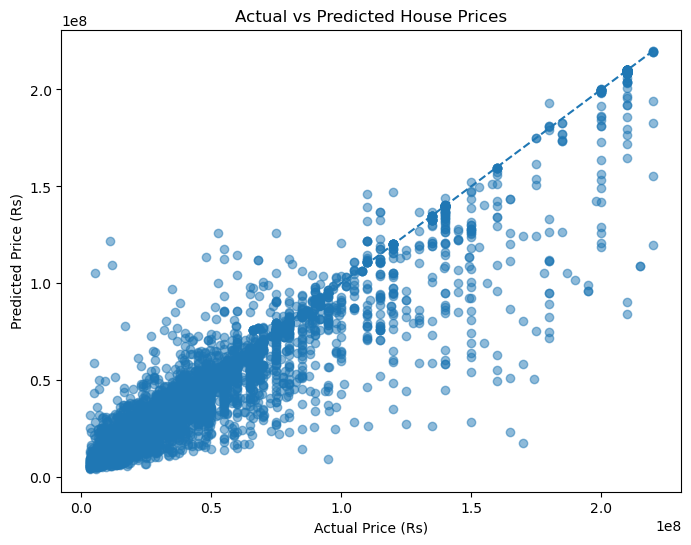

In [129]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_real,
    y_pred_real,
    alpha=0.5
)

plt.xlabel('Actual Price (Rs)')
plt.ylabel('Predicted Price (Rs)')
plt.title('Actual vs Predicted House Prices')

# Perfect prediction line
plt.plot(
    [y_test_real.min(), y_test_real.max()],
    [y_test_real.min(), y_test_real.max()],
    linestyle="--"
)

plt.show()

In [130]:
error_df = pd.DataFrame({
    "actual_price": y_test_real,
    "predicted_price": y_pred_real
})

error_df["error"] = (
    error_df["actual_price"] - error_df["predicted_price"]
)

error_df["absolute_error"] = error_df["error"].abs()

error_df.head()

,actual_price,predicted_price,error,absolute_error
38296,7900000.0,8.520955e+06,-6.209555e+05,6.209555e+05
26352,50000000.0,3.478346e+07,1.521654e+07,1.521654e+07
43041,13500000.0,1.598400e+07,-2.484004e+06,2.484004e+06
1643,38000000.0,4.392153e+07,-5.921526e+06,5.921526e+06
38096,23500000.0,2.347344e+07,2.655688e+04,2.655688e+04


In [131]:
error_df.sort_values(
    "absolute_error",
    ascending=False
).head(10)

,actual_price,predicted_price,error,absolute_error
33351,170000000.0,1.740973e+07,1.525903e+08,1.525903e+08
24214,165000000.0,2.317218e+07,1.418278e+08,1.418278e+08
47694,210000000.0,8.418323e+07,1.258168e+08,1.258168e+08
11667,174000000.0,5.075003e+07,1.232500e+08,1.232500e+08
49567,150000000.0,2.837850e+07,1.216215e+08,1.216215e+08
7059,210000000.0,9.010882e+07,1.198912e+08,1.198912e+08
22618,165000000.0,5.128912e+07,1.137109e+08,1.137109e+08
10517,170000000.0,5.841534e+07,1.115847e+08,1.115847e+08
22355,11000000.0,1.220536e+08,-1.110536e+08,1.110536e+08
16140,160000000.0,4.966599e+07,1.103340e+08,1.103340e+08


In [132]:
y_test_real.describe()

count    9.708000e+03
mean     3.900802e+07
std      3.475365e+07
min      3.300000e+06
25%      1.850000e+07
50%      2.900000e+07
75%      4.700000e+07
max      2.200000e+08
Name: price, dtype: float64

In [133]:
(y_test_real > 100_000_000).sum()

np.int64(538)

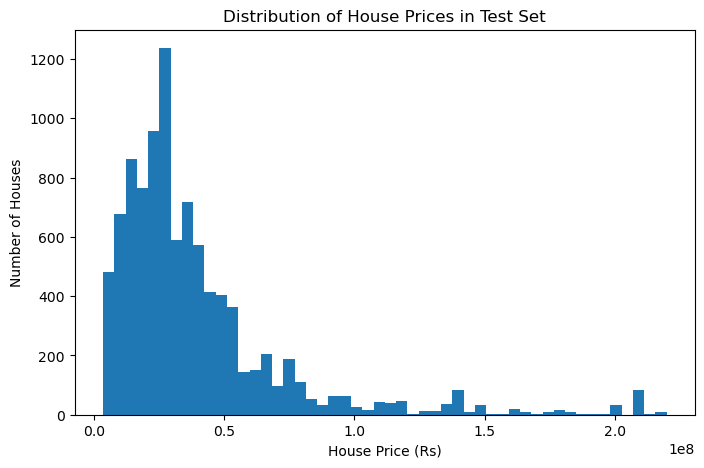

In [134]:
plt.figure(figsize=(8, 5))

plt.hist(y_test_real, bins=50)

plt.xlabel("House Price (Rs)")
plt.ylabel("Number of Houses")
plt.title("Distribution of House Prices in Test Set")

plt.show()

In [135]:
error_df["price_group"] = pd.cut(
    error_df["actual_price"],
    bins=[0, 25_000_000, 50_000_000, 100_000_000, np.inf],
    labels=["<25M", "25M-50M", "50M-100M", "100M+"]
)

error_df.groupby("price_group", observed=True).agg(
    mae=("absolute_error", "mean"),
    count=("actual_price", "count")
)


,mae,count
price_group,,
<25M,3.140625e+06,3892
25M-50M,3.780421e+06,3788
50M-100M,8.399050e+06,1490
100M+,2.219469e+07,538



### Error Analysis by Price Range

The model performs reasonably well for houses below Rs. 50 million, with MAEs of around Rs. 3.2–3.7 million. The error increases for more expensive properties, reaching about Rs. 22.2 million for houses above Rs. 100 million. This suggests that the model has more difficulty predicting high-value properties, which may be because there are fewer examples of these properties in the dataset.`

In [136]:
feature_names = final_model.named_steps["preprocess"].get_feature_names_out()

In [137]:
importances = final_model.named_steps["model"].feature_importances_

In [138]:
feature_importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
})

feature_importance_df = feature_importance_df.sort_values(
    "importance",
    ascending=False
)

feature_importance_df.head(20)

,feature,importance
1,num__bathrooms,0.537819
2,num__house_size,0.236490
4,num__house_size_per_land_size,0.040211
3,num__land_size,0.037999
7,bool__is_member,0.017464
0,num__bedrooms,0.017453
62,cat_highcard__location_infrequent_sklearn,0.012485
67,cat_highcard__exact_area_Colombo,0.009384
10,cat__geo_region_LK-11,0.008833
36,cat_highcard__location_Dehiwala,0.006333


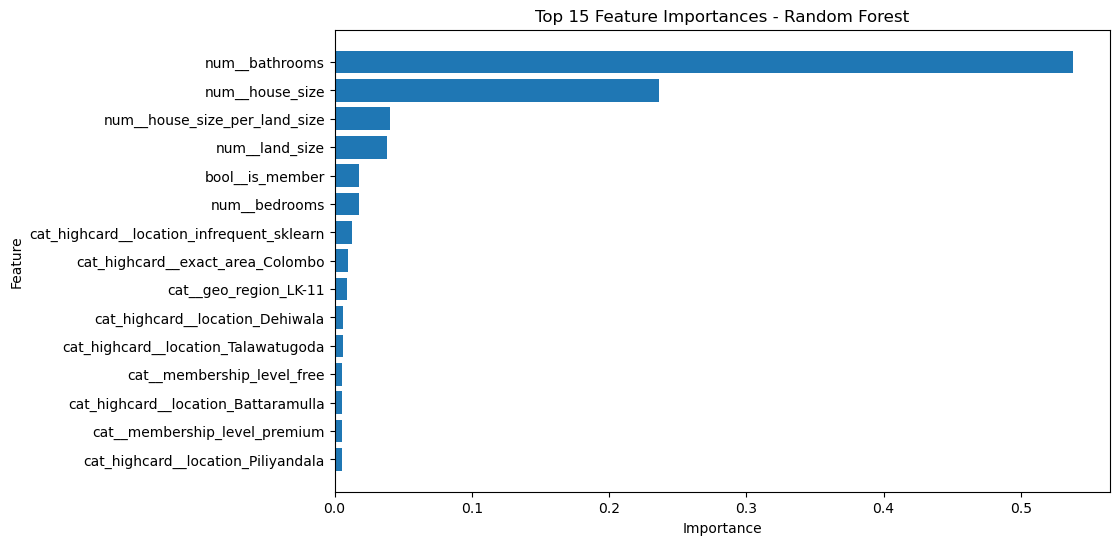

In [139]:
top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["feature"][::-1],
    top_features["importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Feature Importances - Random Forest")

plt.show()

In [140]:
houses_df.groupby("bathrooms")["price"].agg(
    ["count", "mean", "median"]
)

,count,mean,median
bathrooms,,,
1,8009,1.274653e+07,11000000.0
2,14835,2.549447e+07,23500000.0
3,12570,3.923448e+07,33000000.0
4,9557,5.806576e+07,49000000.0
5,2686,9.556923e+07,76000000.0
6,524,8.071647e+07,70000000.0
7,149,1.368547e+08,150000000.0
8,29,1.216897e+08,120000000.0
9,71,1.458380e+08,115000000.0


In [141]:
import joblib

joblib.dump(final_model, "house_price_model.pkl")

['house_price_model.pkl']